# Query-based detection — evaluation of trained checkpoints

This notebook evaluates the three RT-DETR-L configurations trained in `06_query_experiments` (8 epochs each, step-5 subset) and the 12 saved RetinaNet epochs from the anchor-based experiments. No training is performed here.

All models are evaluated on the same 570 validation images with the same COCO bbox protocol, which gives per-epoch mAP curves, AP by object size, and AP on sparse and dense frames.

In [1]:
# Configuration: paths and reference models only; all training is disabled.
HF_REPO = 'lilialania/visdrone-retinanet'
RT_PREFIX = 'query_rtdetr_step5_clean_coco_8epochs'   # actual prefix in the training notebook
RT_NAMES = ['reference_step5', 'queries200_step5', 'matching_step5']
RT_EPOCHS = list(range(1, 9))
CNN_PREFIX = 'checkpoints'                           # RetinaNet baseline: epoch_01.pt ... epoch_12.pt
CNN_EPOCHS = list(range(1, 13))
COCO_STEP = 5
IMGSZ_RT = 640
CONF_RT = 0.01
MAX_DETECTIONS = 500
COMPARE_EPOCHS = 8
RUN_CNN_EPOCHS = True
RUN_RT_EPOCHS = True
RUN_FINAL_MODELS = True
RUN_DENSE_SCENE_AP = True
UPLOAD_METRICS_TO_HF = True  # small JSON results survive Kaggle resets
METRIC_HF_PREFIX = 'query_step5_evaluation_metrics_v1'
# Can change to None to allow automatic discovery; explicit override is preferred if mounted at another location.
DATA_ROOT_OVERRIDE = '/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026'
# Filename can be 'epoch_01.pt' stored under each experiment, as in training backup.
OUTPUT_DIR = '/kaggle/working/query_step5_final_evaluation'
print('Evaluation only: no train() calls in this notebook')

Evaluation only: no train() calls in this notebook


## 1. Dependencies and Hugging Face access

Installs dependencies and authenticates to the private Hugging Face repository with the `HF_TOKEN` secret.

In [2]:
import sys, subprocess, os, json, time, shutil, warnings, traceback, hashlib, gc
from pathlib import Path
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.210', 'huggingface_hub', 'pycocotools', 'matplotlib', 'pandas', 'torchvision'],check=True)
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torchvision, ultralytics
from PIL import Image
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download
from kaggle_secrets import UserSecretsClient
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import RTDETR
#assert torch.cuda.is_available(), 'Enable GPU in Kaggle settings.'
assert ultralytics.__version__ == '8.4.210', ultralytics.__version__
HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN').strip()
assert HF_TOKEN, 'Enable HF_TOKEN under Kaggle Add-ons > Secrets.'
api = HfApi(token=HF_TOKEN)
api.repo_info(repo_id=HF_REPO, repo_type='model', token=HF_TOKEN)
print('HF access OK:', api.whoami()['name'])
#print('GPU:',torch.cuda.get_device_name(0), 'torchvision:', torchvision.__version__)
OUT=Path(OUTPUT_DIR);OUT.mkdir(parents=True,exist_ok=True)
CKPT_CACHE=OUT/'checkpoint_temp'; CKPT_CACHE.mkdir(exist_ok=True)
METRICS=OUT/'metrics'; METRICS.mkdir(exist_ok=True)
PRED_DIR=OUT/'final_predictions';PRED_DIR.mkdir(exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
HF access OK: lilialania


## 2. Validation image selection

The evaluation subset is `sorted(COCO image IDs)[::5]`, which gives **570 of 2,846** validation images. The SHA-256 of the selected IDs is printed so that the subset can be reproduced. 

In [3]:
root=Path(DATA_ROOT_OVERRIDE)
if not (root/'val'/'annotations_coco.json').exists():
    candidates=list(Path('/kaggle/input').glob('**/val/annotations_coco.json'))
    assert len(candidates)==1, f'Cannot uniquely locate VisDrone val annotations: {candidates}'
    root=candidates[0].parent.parent
VAL=root/'val'
assert (VAL/'annotations_coco.json').is_file(), VAL
coco=COCO(str(VAL/'annotations_coco.json'))
IMG_IDS=sorted(coco.getImgIds())[::COCO_STEP]
assert len(IMG_IDS)>100, f'Step-5 val unexpectedly small: {len(IMG_IDS)}'
# Resolve paths using metadata + only a bounded number of index scans; no src.* dependency.
image_files={}
all_image_paths=list(VAL.rglob('*.jpg'))+list(VAL.rglob('*.png'))+list(VAL.rglob('*.jpeg'))
by_rel={p.relative_to(VAL).as_posix():p for p in all_image_paths}
by_base={}
for p in all_image_paths:by_base.setdefault(p.name,[]).append(p)
for imgid in IMG_IDS:
    name=Path(coco.imgs[imgid]['file_name']).as_posix()
    candidates=[VAL/name, VAL/'images'/name, VAL/'images'/Path(name).name]
    path=next((x for x in candidates if x.is_file()),None)
    if path is None:
        hits=[p for relative,p in by_rel.items() if relative.endswith('/'+name) or relative==name]
        if not hits:hits=by_base.get(Path(name).name,[])
        assert len(hits)==1, f'Image not uniquely found: id={imgid}, name={name}, choices={hits[:5]}'
        path=hits[0]
    image_files[imgid]=path
assert len(image_files)==len(IMG_IDS)
ID_SIGNATURE=hashlib.sha256(','.join(map(str,IMG_IDS)).encode()).hexdigest()
print('Original validation:',len(coco.getImgIds()),'Selected every fifth:',len(IMG_IDS))
print('Selected-ID SHA256:',ID_SIGNATURE)
print('First image:',next(iter(image_files.values())))
print('Ground truth categories:',[(cid,c['name']) for cid,c in sorted(coco.cats.items())])
(OUT/'protocol.json').write_text(json.dumps({'data_root':str(root),'ids':IMG_IDS,'id_sha256':ID_SIGNATURE,'step':COCO_STEP,'rt_imgsz':IMGSZ_RT,'conf':CONF_RT,'max_dets':MAX_DETECTIONS},indent=2))

loading annotations into memory...
Done (t=0.68s)
creating index...
index created!
Original validation: 2846 Selected every fifth: 570
Selected-ID SHA256: c87032d1a8ab4e4c29643322f222dc2a48adacbd566a50a8111d97376cfd6cf2
First image: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/val/images/uav0000086_00000_v/0000001.jpg
Ground truth categories: [(1, 'person'), (2, 'bicycle'), (3, 'car'), (4, 'van'), (5, 'truck'), (6, 'tricycle'), (7, 'bus'), (8, 'motor')]


5739

## 3. Hugging Face file inventory and resumable checkpoint retrieval

The previous training used `query_rtdetr_step5_clean_coco_8epochs/{name}/epoch_XX.pt` for per-epoch backup. This cell **inspects actual remote files** before any GPU evaluation, and fails with concrete missing paths. CNN checkpoint naming follows `checkpoints/epoch_XX.pt`.

In [4]:
remote_files=set(api.list_repo_files(repo_id=HF_REPO,repo_type='model',token=HF_TOKEN))
rt_remote=lambda name,ep: f'{RT_PREFIX}/{name}/epoch_{ep:02d}.pt'
cnn_remote=lambda ep: f'{CNN_PREFIX}/epoch_{ep:02d}.pt'
missing_rt=[rt_remote(name,e) for name in RT_NAMES for e in RT_EPOCHS if rt_remote(name,e) not in remote_files]
missing_cnn=[cnn_remote(e) for e in CNN_EPOCHS if cnn_remote(e) not in remote_files]
print('RT 8-epoch weights available:',24-len(missing_rt),'/24')
print('RetinaNet weights available:',12-len(missing_cnn),'/12')
if missing_rt:print('Missing RT:',missing_rt)
if missing_cnn:print('Missing CNN:',missing_cnn)
assert not missing_rt, 'Some RT-DETR epoch checkpoints are missing; fix prefix/backup before evaluation.'
assert not missing_cnn, 'Some RetinaNet epoch checkpoints are missing; fix prefix before evaluation.'
def download_ckpt(remote_path):
    return Path(hf_hub_download(repo_id=HF_REPO,filename=remote_path,repo_type='model',token=HF_TOKEN,
        local_dir=str(CKPT_CACHE)))

RT 8-epoch weights available: 24 /24
RetinaNet weights available: 12 /12


## 4. Checkpoint compatibility smoke tests (before the long run)

RetinaNet older checkpoints may contain a model state dictionary or a wrapped dictionary. We **infer the class count from head weights**, rebuild torchvision `retinanet_resnet50_fpn_v2`, and require strict weight compatibility. No `src.retinanet` module is imported. If weights represent a custom architecture or head, this stops with diagnostics instead of silently evaluating the wrong detector.

In [5]:
from torchvision.models.detection import retinanet_resnet50_fpn_v2
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
def unwrap_checkpoint(path):
    raw=torch.load(path,map_location='cpu',weights_only=False)
    if isinstance(raw,torch.nn.Module):
        return raw, {'format':'nn.Module'}
    if isinstance(raw,dict):
        for k in ('model','model_state_dict','state_dict','weights','net'):
            v=raw.get(k)
            if isinstance(v,torch.nn.Module):return v,{'format':'module key '+k,'keys':list(raw)[:30]}
            if isinstance(v,dict) and v and all(isinstance(key,str) for key in v):
                return v,{'format':'state_dict key '+k,'keys':list(raw)[:30], 'metadata':{x:raw.get(x) for x in ['epoch','min_size','max_size','num_classes'] if x in raw}}
        if raw and all(isinstance(v,torch.Tensor) for v in raw.values()):return raw,{'format':'raw_state_dict'}
        raise RuntimeError(f'Unknown checkpoint dict keys: {list(raw)[:35]}')
    raise RuntimeError(f'Unsupported checkpoint type: {type(raw)}')

def load_retinanet(path):
    item,details=unwrap_checkpoint(path)
    if isinstance(item,torch.nn.Module):
        model=item
    else:
        state={k.removeprefix('module.'):v for k,v in item.items()}
        candidates=[(k,v.shape) for k,v in state.items() if 'classification_head.cls_logits.weight' in k]
        assert len(candidates)==1, f'No unique RetinaNet class head tensor. Examples: {list(state)[:25]}'
        headkey,shape=candidates[0]
        anchors_per_loc=9   # standard torchvision RetinaNet head; check against actual tensors below
        assert shape[0]%anchors_per_loc==0, (headkey,shape)
        num_classes=shape[0]//anchors_per_loc
        assert num_classes in (8,9,10), f'Unexpected class count inferred: {num_classes}, tensor {shape}'
        model = retinanet_resnet50_fpn_v2(
        weights=None,
        weights_backbone=None,
        min_size=details.get("min_size", 640),
        max_size=details.get("max_size", 1280),
        detections_per_img=300,
        )
        model.head.classification_head = RetinaNetClassificationHead(
            model.backbone.out_channels,
            model.anchor_generator.num_anchors_per_location()[0],
            9,
        )
        try:model.load_state_dict(state,strict=True)
        except RuntimeError as exc:
            raise RuntimeError('RetinaNet checkpoint differs from torchvision retinanet_resnet50_fpn_v2. '+
              'Use the original training build_model implementation or inspect architecture before continuing. '+str(exc)[:2000]) from exc
        details['num_classes']=num_classes
    assert isinstance(model,torchvision.models.detection.RetinaNet),f'Wrong model type: {type(model)}'
    # Detection labels: the original torchvision model convention is 1..K for foreground.
    model.detections_per_img=MAX_DETECTIONS
    model.eval().to('cuda:0')
    return model,details

# One checkpoint per architecture first. Clean up VRAM after each test.
retina_smoke=download_ckpt(cnn_remote(1))
import torch

ckpt = torch.load(
    retina_smoke,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(ckpt))

if isinstance(ckpt, dict):
    print("Top-level keys:", list(ckpt.keys()))

state = ckpt.get("model", ckpt.get("state_dict", ckpt))

if isinstance(state, torch.nn.Module):
    state = state.state_dict()

print("\nClassification head keys:")
for key, value in state.items():
    if "head.classification_head.conv" in key:
        print(key, tuple(value.shape))
model,retina_format=load_retinanet(retina_smoke)
print('RetinaNet compatible:',retina_format)
with torch.inference_mode():
    im=Image.open(image_files[IMG_IDS[0]]).convert('RGB')
    result=model([to_tensor(im).cuda()])[0]
    print('RetinaNet test detections:',len(result['scores']))
del model;gc.collect();torch.cuda.empty_cache()
rt_smoke=download_ckpt(rt_remote('matching_step5',1))
rtmodel=RTDETR(str(rt_smoke))
print('RT-DETR class names:',rtmodel.names)
assert len(rtmodel.names)==8, 'Expected eight VisDrone foreground classes'
print('RT-DETR model load compatible')
del rtmodel;gc.collect();torch.cuda.empty_cache()

checkpoints/epoch_01.pt: reconstructing file:   0%|          |  0.00B /  291MB            

checkpoints/epoch_01.pt: downloading bytes:           |  0.00B            

Checkpoint type: <class 'dict'>
Top-level keys: ['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler', 'epoch', 'epochs']

Classification head keys:
head.classification_head.conv.0.0.weight (256, 256, 3, 3)
head.classification_head.conv.0.0.bias (256,)
head.classification_head.conv.1.0.weight (256, 256, 3, 3)
head.classification_head.conv.1.0.bias (256,)
head.classification_head.conv.2.0.weight (256, 256, 3, 3)
head.classification_head.conv.2.0.bias (256,)
head.classification_head.conv.3.0.weight (256, 256, 3, 3)
head.classification_head.conv.3.0.bias (256,)
RetinaNet compatible: {'format': 'state_dict key model', 'keys': ['model', 'min_size', 'max_size', 'optimizer', 'scheduler', 'scaler', 'epoch', 'epochs'], 'metadata': {'epoch': 1, 'min_size': 640, 'max_size': 1280}, 'num_classes': 9}
RetinaNet test detections: 123


query_rtdetr_step5_clean_coco_8epochs/ma(…): reconstructing file:   0%|          |  0.00B /  329MB            

query_rtdetr_step5_clean_coco_8epochs/ma(…): downloading bytes:           |  0.00B            

RT-DETR class names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'van', 4: 'truck', 5: 'tricycle', 6: 'bus', 7: 'motor'}
RT-DETR model load compatible


In [6]:
import torch

from torchvision.models.detection import retinanet_resnet50_fpn_v2
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

# Original architecture from retinanet.py
model = retinanet_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    min_size=ckpt.get("min_size", 640),
    max_size=ckpt.get("max_size", 1280),
    detections_per_img=300,
)

num_classes = 9
in_channels = model.backbone.out_channels
num_anchors = model.anchor_generator.num_anchors_per_location()[0]

model.head.classification_head = RetinaNetClassificationHead(
    in_channels,
    num_anchors,
    num_classes,
)

# Load the original checkpoint
state = ckpt["model"]

try:
    model.load_state_dict(state, strict=True)
    print("SUCCESS! Original RetinaNet checkpoint loaded correctly.")
except RuntimeError as e:
    print("Still incompatible:")
    print(str(e)[:4000])

SUCCESS! Original RetinaNet checkpoint loaded correctly.


## 5. Matched COCO evaluation engine

Both detectors output bounding boxes in original image coordinates and use the **same GT COCO file, 570 frame IDs, category mapping, max detections and COCO evaluation**. Architectural input transforms can differ (RetinaNet min/max size 640/1280 vs RT-DETR 640 square); this is disclosed.

COCO AP by size and by dense-image group is computed from predictions, **not** from validation loss. No NMS is added to RT-DETR.

In [7]:
CAT_IDS=sorted(coco.cats)
# Dataset uses 8 classes. Checkpoint class 0..7 maps to COCO IDs by category names, not unsupported assumption id+1.
def normal_name(x):return str(x).lower().strip().replace('_',' ').replace('-',' ')
coco_names={normal_name(v['name']):int(k) for k,v in coco.cats.items()}
assert len(coco_names)==8, coco_names

def map_rt_names(names):
    mapping={int(k):coco_names.get(normal_name(v)) for k,v in names.items()}
    assert len(mapping)==8 and all(v is not None for v in mapping.values()), (mapping,coco_names)
    assert len(set(mapping.values()))==8, mapping
    return mapping

# RetinaNet training used torchvision's 1-indexed foreground label convention.
# Check with known dataset 8 classes and inferred 9 head outputs (including background).
def retina_category_mapping(details):
    n=details.get('num_classes')
    assert n in (8,9), ('Unexpected RetinaNet classification head class count',n)
    # torchvision foreground indices are 0..7 when num_classes=8, or 1..8 when a background slot is included.
    # Confirm convention against the original training code before interpreting AP.
    return {(i if n==8 else i+1): CAT_IDS[i] for i in range(8)}

RT_MAP=map_rt_names(RTDETR(str(rt_smoke)).names)
RETINA_MAP=retina_category_mapping(retina_format)
print('RT class mapping:',RT_MAP)
print('RetinaNet assumed 1-index foreground:',RETINA_MAP)
assert set(RT_MAP.values())==set(RETINA_MAP.values())==set(CAT_IDS)

# If your old RetinaNet dataset class order is not COCO cat-ID order, edit RETINA_MAP now.
# A visual cross-check is mandatory; this is not recoverable from a raw state_dict alone.

RT class mapping: {0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8}
RetinaNet assumed 1-index foreground: {1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8}


In [8]:
def atomic_write_json(path,data):
    p=Path(path);p.parent.mkdir(parents=True,exist_ok=True)
    temp=p.with_suffix('.json.tmp');temp.write_text(json.dumps(data,indent=2,ensure_ascii=False))
    temp.replace(p)

def coco_metrics(preds,sub_ids):
    # COCO.loadRes requires at least one prediction. An empty prediction set has AP=0.
    if not preds:
        return {k:0. for k in ['mAP50_95','AP50','AP75','AP_small','AP_medium','AP_large']}
    det=coco.loadRes(preds)
    ev=COCOeval(coco,det,'bbox')
    ev.params.imgIds=list(sub_ids)
    ev.params.maxDets=[1,100,MAX_DETECTIONS]
    ev.evaluate();ev.accumulate();ev.summarize()
    p=ev.eval['precision'][:,:,:,:,-1] # IoU, recall, K, area; last maxDets
    def avg(arr):
        valid=arr[arr>-1]
        return float(valid.mean()) if valid.size else None
    return {'mAP50_95':avg(p[:,:,:,0]),'AP50':avg(p[0,:,:,0]),'AP75':avg(p[5,:,:,0]),
            'AP_small':avg(p[:,:,:,1]),'AP_medium':avg(p[:,:,:,2]),'AP_large':avg(p[:,:,:,3])}

def predict_retinanet(model):
    preds=[];seconds=0.;n=0
    for j,imgid in enumerate(IMG_IDS):
        tensor=to_tensor(Image.open(image_files[imgid]).convert('RGB')).to('cuda:0')
        torch.cuda.synchronize();start=time.perf_counter()
        with torch.inference_mode():out=model([tensor])[0]
        torch.cuda.synchronize()
        if j>0:seconds+=time.perf_counter()-start;n+=1
        for box,score,cls in zip(out['boxes'].detach().cpu().tolist(),out['scores'].detach().cpu().tolist(),out['labels'].detach().cpu().tolist()):
            cls=int(cls)
            if cls not in RETINA_MAP: continue
            x1,y1,x2,y2=box
            if x2<=x1 or y2<=y1:continue
            preds.append(dict(image_id=int(imgid),category_id=RETINA_MAP[cls],bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],score=float(score)))
        if (j+1)%100==0: print('CNN images:',j+1,'/',len(IMG_IDS),flush=True)
    return preds, 1000*seconds/max(n,1)

def predict_rtdetr(model):
    mapping=map_rt_names(model.names)
    preds=[];seconds=0.;n=0
    for j,imgid in enumerate(IMG_IDS):
        p=image_files[imgid]
        torch.cuda.synchronize();start=time.perf_counter()
        r=model.predict(str(p),imgsz=IMGSZ_RT,conf=CONF_RT,max_det=MAX_DETECTIONS,device=0,verbose=False)[0]
        torch.cuda.synchronize()
        if j>0:seconds+=time.perf_counter()-start;n+=1
        if r.boxes is not None:
            for box,score,cls in zip(r.boxes.xyxy.cpu().tolist(),r.boxes.conf.cpu().tolist(),r.boxes.cls.int().cpu().tolist()):
                x1,y1,x2,y2=box; cls=int(cls)
                if x2<=x1 or y2<=y1:continue
                preds.append(dict(image_id=int(imgid),category_id=mapping[cls],bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],score=float(score)))
        if (j+1)%100==0: print('RT images:',j+1,'/',len(IMG_IDS),flush=True)
    return preds,1000*seconds/max(n,1)

def eval_ckpt(model_kind,remote_path,tag,save_preds=False):
    metrics_path=METRICS/f'{tag}.json'
    predpath=PRED_DIR/f'{tag}.json'
    if not metrics_path.is_file() and UPLOAD_METRICS_TO_HF:
        remote_metric=f'{METRIC_HF_PREFIX}/{tag}.json'
        if api.file_exists(repo_id=HF_REPO,filename=remote_metric,repo_type='model',token=HF_TOKEN):
            src=Path(hf_hub_download(repo_id=HF_REPO,filename=remote_metric,repo_type='model',token=HF_TOKEN))
            metrics_path.write_bytes(src.read_bytes())
    if metrics_path.is_file():
        data=json.loads(metrics_path.read_text())
        if data.get('id_sha256')==ID_SIGNATURE and data.get('checkpoint_remote')==remote_path and data.get('max_dets')==MAX_DETECTIONS:
            if (not save_preds) or predpath.is_file():
                print('CACHED',tag, 'mAP:', data['mAP50_95']);return data
    print('EVALUATING',tag,remote_path,flush=True)
    weights=download_ckpt(remote_path)
    if model_kind=='cnn':
        model,details=load_retinanet(weights)
        current_map=retina_category_mapping(details)
        assert current_map==RETINA_MAP, 'RetinaNet mapping changed'
        preds,ms=predict_retinanet(model)
    else:
        model=RTDETR(str(weights))
        preds,ms=predict_rtdetr(model)
    result={'model':tag,'checkpoint_remote':remote_path,'id_sha256':ID_SIGNATURE,
       'images_evaluated':len(IMG_IDS),'max_dets':MAX_DETECTIONS,'ms_per_image':ms,
       'detections':len(preds),'architecture':model_kind,'step':COCO_STEP,
       **coco_metrics(preds,IMG_IDS)}
    if save_preds:atomic_write_json(predpath,preds)
    atomic_write_json(metrics_path,result)
    if UPLOAD_METRICS_TO_HF:
        api.upload_file(path_or_fileobj=str(metrics_path),path_in_repo=f'{METRIC_HF_PREFIX}/{tag}.json',
                        repo_id=HF_REPO,repo_type='model',token=HF_TOKEN,
                        commit_message=f'Cache evaluation {tag}')
    print('DONE',tag, 'mAP:',result['mAP50_95'],flush=True)
    del model,preds;gc.collect();torch.cuda.empty_cache()
    # Leave HF cache alone by default (helps resume), but exclude weights from output ZIP.
    return result

## 6. Per-checkpoint COCO evaluation

Each checkpoint is evaluated independently and its metrics are cached as JSON. In total there are 20 evaluations (12 RetinaNet + 8 RT-DETR epochs). The comparison plot shows the first 8 epochs of both models; the GPU budgets are not equal.

In [9]:
cnn_rows=[];rt_rows=[]
if RUN_CNN_EPOCHS:
    for ep in CNN_EPOCHS:
        row=eval_ckpt('cnn',cnn_remote(ep),f'retina_epoch_{ep:02d}',save_preds=(ep==12 and RUN_DENSE_SCENE_AP))
        cnn_rows.append({'epoch':ep,**row})
    pd.DataFrame(cnn_rows).to_csv(OUT/'retina_by_epoch.csv',index=False)
if RUN_RT_EPOCHS:
    for ep in RT_EPOCHS:
        row=eval_ckpt('rt',rt_remote('matching_step5',ep),f'rt_matching_epoch_{ep:02d}',
                      save_preds=(ep==8 and RUN_DENSE_SCENE_AP))
        rt_rows.append({'epoch':ep,**row})
    pd.DataFrame(rt_rows).to_csv(OUT/'rtdetr_matching_by_epoch.csv',index=False)
assert len(cnn_rows)==12 and len(rt_rows)==8, 'Cannot produce requested matched curves with missing epoch results.'
print('Per-epoch evaluation complete')

EVALUATING retina_epoch_01 checkpoints/epoch_01.pt
CNN images: 100 / 570
CNN images: 200 / 570
CNN images: 300 / 570
CNN images: 400 / 570
CNN images: 500 / 570
Loading and preparing results...
DONE (t=0.42s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=23.81s).
Accumulating evaluation results...
DONE (t=1.44s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.108
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.209
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.097
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.041
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.099
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.241
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.065
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=

checkpoints/epoch_02.pt: reconstructing file:   0%|          |  0.00B /  291MB            

checkpoints/epoch_02.pt: downloading bytes:           |  0.00B            

CNN images: 100 / 570
CNN images: 200 / 570
CNN images: 300 / 570
CNN images: 400 / 570
CNN images: 500 / 570
Loading and preparing results...
DONE (t=0.43s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=24.44s).
Accumulating evaluation results...
DONE (t=1.44s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.130
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.249
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.122
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.038
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.116
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.286
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.072
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.321
 Average Recall     (AR) @[ IoU=0.50:

checkpoints/epoch_03.pt: reconstructing file:   0%|          |  0.00B /  291MB            

checkpoints/epoch_03.pt: downloading bytes:           |  0.00B            

... (45 outputs left out)

RT images: 100 / 570
RT images: 200 / 570
RT images: 300 / 570
RT images: 400 / 570
RT images: 500 / 570
Loading and preparing results...
DONE (t=0.56s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=45.75s).
Accumulating evaluation results...
DONE (t=2.09s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.036
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.009
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.018
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.043
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.027
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.147
 Average Recall     (AR) @[ IoU=0.50:0.95 

query_rtdetr_step5_clean_coco_8epochs/ma(…): reconstructing file:   0%|          |  0.00B /  329MB            

query_rtdetr_step5_clean_coco_8epochs/ma(…): downloading bytes:           |  0.00B            

RT images: 100 / 570
RT images: 200 / 570
RT images: 300 / 570
RT images: 400 / 570
RT images: 500 / 570
Loading and preparing results...
DONE (t=0.55s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=46.13s).
Accumulating evaluation results...
DONE (t=2.10s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.037
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.009
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.019
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.044
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.028
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.153
 Average Recall     (AR) @[ IoU=0.50:0.95 

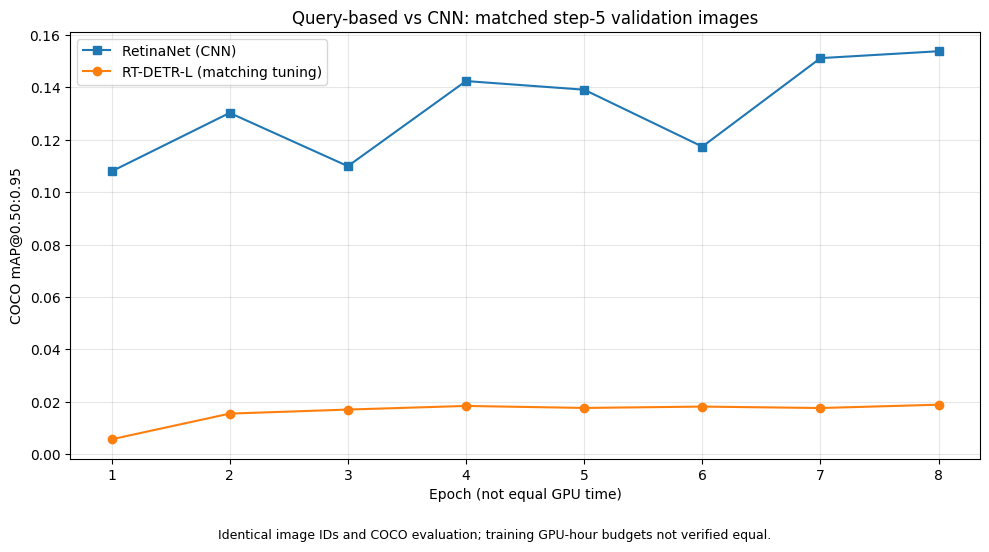

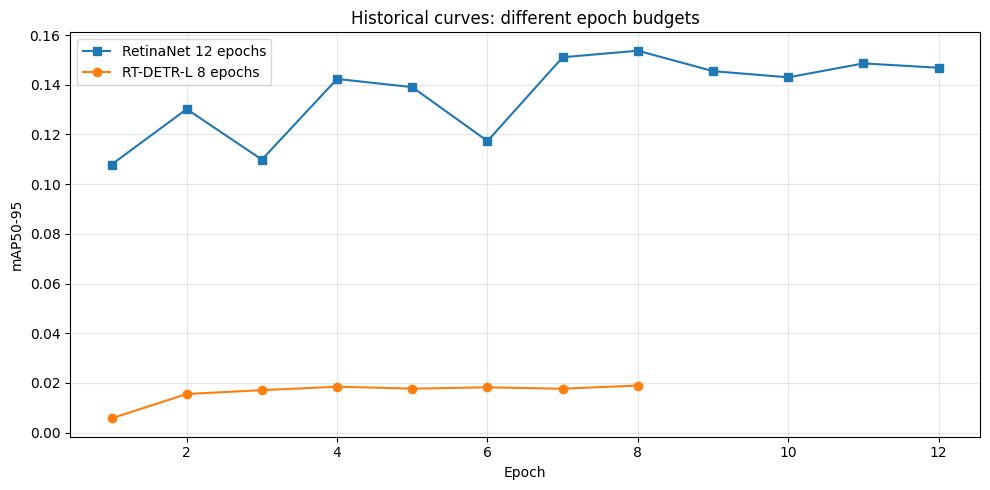

,family,epoch,mAP50_95,AP50,AP_small,AP_medium,AP_large,ms_per_image
0,RetinaNet,1,0.107888,0.209166,0.040960,0.099150,0.241099,132.992800
1,RetinaNet,2,0.130202,0.248700,0.038148,0.115659,0.285568,137.679527
2,RetinaNet,3,0.109887,0.217616,0.037769,0.098986,0.244005,137.694260
3,RetinaNet,4,0.142342,0.278887,0.046661,0.127550,0.314589,137.594996
4,RetinaNet,5,0.139049,0.276220,0.040065,0.129243,0.302541,137.785482
5,RetinaNet,6,0.117343,0.230853,0.031802,0.109584,0.256069,137.389550
6,RetinaNet,7,0.151088,0.296481,0.046335,0.133456,0.324768,138.073571
7,RetinaNet,8,0.153712,0.294862,0.047691,0.135396,0.325923,137.467471
8,RetinaNet,9,0.145490,0.280573,0.043960,0.132837,0.307557,137.571863
9,RetinaNet,10,0.142999,0.277770,0.040858,0.132091,0.304017,137.450827


In [10]:
cnn_df=pd.DataFrame(cnn_rows).sort_values('epoch')
rt_df=pd.DataFrame(rt_rows).sort_values('epoch')
fig,ax=plt.subplots(figsize=(10,5.5))
ax.plot(cnn_df.query('epoch <= @COMPARE_EPOCHS')['epoch'],cnn_df.query('epoch <= @COMPARE_EPOCHS')['mAP50_95'],marker='s',label='RetinaNet (CNN)')
ax.plot(rt_df['epoch'],rt_df['mAP50_95'],marker='o',label='RT-DETR-L (matching tuning)')
ax.set(xlabel='Epoch (not equal GPU time)',ylabel='COCO mAP@0.50:0.95',title='Query-based vs CNN: matched step-5 validation images')
ax.set_xticks(range(1,COMPARE_EPOCHS+1));ax.legend();ax.grid(alpha=.3)
fig.text(.5,.01,'Identical image IDs and COCO evaluation; training GPU-hour budgets not verified equal.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(OUT/'cnn_vs_query_map_by_epoch.png',dpi=180);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(cnn_df.epoch,cnn_df.mAP50_95,'s-',label='RetinaNet 12 epochs')
ax.plot(rt_df.epoch,rt_df.mAP50_95,'o-',label='RT-DETR-L 8 epochs')
ax.set(xlabel='Epoch',ylabel='mAP50-95',title='Historical curves: different epoch budgets')
ax.grid(alpha=.3);ax.legend();fig.tight_layout()
fig.savefig(OUT/'historical_curves_unequal_budget.png',dpi=180);plt.show();plt.close(fig)
display(pd.concat([cnn_df.assign(family='RetinaNet'),rt_df.assign(family='RT-DETR-L')])[['family','epoch','mAP50_95','AP50','AP_small','AP_medium','AP_large','ms_per_image']])

## 7. Final tuned-parameter comparison (all three RT-DETR configurations)

The curves use the `matching_step5` run. The final table also evaluates the `reference_step5` and `queries200_step5` **best.pt** checkpoints (if backed up), or epoch 8 as a clearly named fallback. Do not label epoch 8 as best.pt.

In [11]:
final_rows=[]
if RUN_FINAL_MODELS:
    for name in RT_NAMES:
        best=f'{RT_PREFIX}/{name}/weights/best.pt'
        remote=best if best in remote_files else rt_remote(name,8)
        print(name,'selected checkpoint:',remote)
        result=eval_ckpt('rt',remote,f'final_{name}',save_preds=RUN_DENSE_SCENE_AP)
        final_rows.append({'configuration':name,'best_available':remote==best,**result})
    # RetinaNet epoch 12 is the historical baseline, explicitly not tuned small-anchors model.
    final_rows.append({'configuration':'retinanet_baseline_epoch12','best_available':False,
                       **eval_ckpt('cnn',cnn_remote(12),'retina_epoch_12',save_preds=RUN_DENSE_SCENE_AP)})
final=pd.DataFrame(final_rows)
if not final.empty:
    display(final[['configuration','mAP50_95','AP50','AP75','AP_small','AP_medium','AP_large','ms_per_image','checkpoint_remote']])
    final.to_csv(OUT/'final_model_comparison.csv',index=False)

reference_step5 selected checkpoint: query_rtdetr_step5_clean_coco_8epochs/reference_step5/weights/best.pt
EVALUATING final_reference_step5 query_rtdetr_step5_clean_coco_8epochs/reference_step5/weights/best.pt


query_rtdetr_step5_clean_coco_8epochs/re(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr_step5_clean_coco_8epochs/re(…): downloading bytes:           |  0.00B            

RT images: 100 / 570
RT images: 200 / 570
RT images: 300 / 570
RT images: 400 / 570
RT images: 500 / 570
Loading and preparing results...
DONE (t=0.55s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=41.39s).
Accumulating evaluation results...
DONE (t=2.07s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.033
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.016
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.005
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.014
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.045
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.037
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.139
 Average Recall     (AR) @[ IoU=0.50:0.95 

query_rtdetr_step5_clean_coco_8epochs/qu(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr_step5_clean_coco_8epochs/qu(…): downloading bytes:           |  0.00B            

RT images: 100 / 570
RT images: 200 / 570
RT images: 300 / 570
RT images: 400 / 570
RT images: 500 / 570
DONE final_queries200_step5 mAP: 0.0
matching_step5 selected checkpoint: query_rtdetr_step5_clean_coco_8epochs/matching_step5/weights/best.pt
EVALUATING final_matching_step5 query_rtdetr_step5_clean_coco_8epochs/matching_step5/weights/best.pt


query_rtdetr_step5_clean_coco_8epochs/ma(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr_step5_clean_coco_8epochs/ma(…): downloading bytes:           |  0.00B            

RT images: 100 / 570
RT images: 200 / 570
RT images: 300 / 570
RT images: 400 / 570
RT images: 500 / 570
Loading and preparing results...
DONE (t=0.56s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=45.76s).
Accumulating evaluation results...
DONE (t=2.15s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.037
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.017
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.009
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.019
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.044
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.028
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.153
 Average Recall     (AR) @[ IoU=0.50:0.95 

,configuration,mAP50_95,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image,checkpoint_remote
0,reference_step5,0.017103,0.032606,0.015585,0.004994,0.013624,0.045386,86.826058,query_rtdetr_step5_clean_coco_8epochs/referenc...
1,queries200_step5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,87.249979,query_rtdetr_step5_clean_coco_8epochs/queries2...
2,matching_step5,0.018931,0.037129,0.017321,0.009316,0.018924,0.043825,86.266892,query_rtdetr_step5_clean_coco_8epochs/matching...
3,retinanet_baseline_epoch12,0.146841,0.282010,0.135694,0.042262,0.134489,0.310003,137.675991,checkpoints/epoch_12.pt


## 8. Small and **dense-scene** evaluation

This evaluates the same predictions on subsets of images grouped by **ground-truth object count** (bottom/top quartiles). AP on a subset is a diagnostic, not a standard benchmark category. We report AP_small/medium/large for all images and dense-image mAP separately. To avoid selecting trivial cases, use thresholds computed from the validation GT only.

GT per image (min/median/75%/max): 8 37.0 51.75 116
Sparse frames: 164 Dense frames: 143
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.77s).
Accumulating evaluation results...
DONE (t=0.23s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.097
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.132
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.110
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.004
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.508
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.088
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.148
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | m

,model,group,images,mAP50_95,AP_small,AP_medium,AP_large
0,retina_epoch_12,sparse,164,0.097028,0.003815,0.022335,0.508289
1,retina_epoch_12,dense,143,0.183424,0.058613,0.167775,0.371369
2,final_reference_step5,sparse,164,0.008187,0.000000,0.003653,0.044232
3,final_reference_step5,dense,143,0.024558,0.006687,0.021113,0.060663
4,final_queries200_step5,sparse,164,0.000000,0.000000,0.000000,0.000000
5,final_queries200_step5,dense,143,0.000000,0.000000,0.000000,0.000000
6,final_matching_step5,sparse,164,0.018796,0.000000,0.006304,0.079563
7,final_matching_step5,dense,143,0.041809,0.016273,0.038266,0.071690


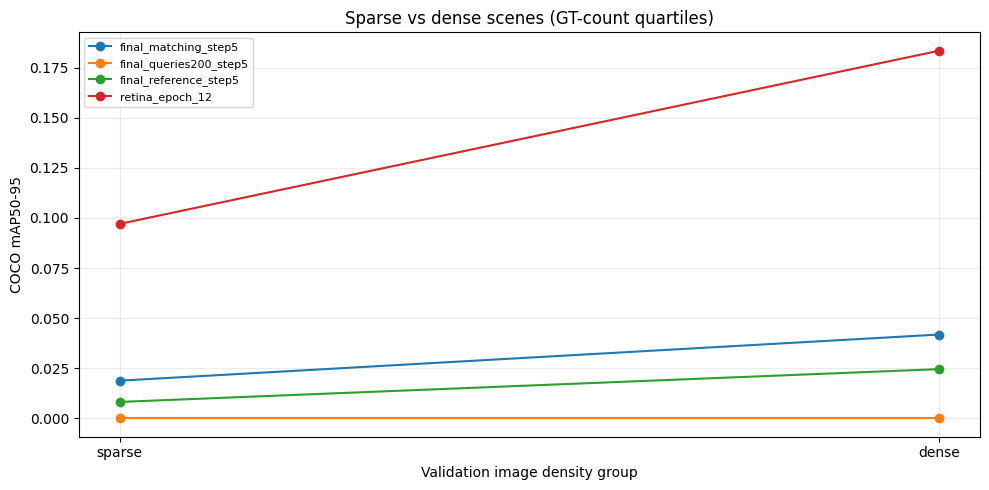

3042

In [12]:
from collections import Counter
counts=Counter(int(a['image_id']) for a in coco.dataset['annotations'] if not a.get('iscrowd',0))
num_per_image=np.array([counts.get(i,0) for i in IMG_IDS])
low=float(np.quantile(num_per_image,.25));high=float(np.quantile(num_per_image,.75))
SPARSE=[i for i in IMG_IDS if counts.get(i,0)<=low]
DENSE=[i for i in IMG_IDS if counts.get(i,0)>=high]
assert SPARSE and DENSE
print('GT per image (min/median/75%/max):',int(num_per_image.min()),np.median(num_per_image),high,int(num_per_image.max()))
print('Sparse frames:',len(SPARSE),'Dense frames:',len(DENSE))
rows=[]
if RUN_DENSE_SCENE_AP:
    for tag in ['retina_epoch_12']+[f'final_{n}' for n in RT_NAMES]:
        path=PRED_DIR/f'{tag}.json'
        assert path.is_file(), f'Missing predictions for dense evaluation: {path}'
        preds=json.loads(path.read_text())
        for group,ids in [('sparse',SPARSE),('dense',DENSE)]:
            chosen=set(ids); subset=[p for p in preds if p['image_id'] in chosen]
            mm=coco_metrics(subset,ids)
            rows.append(dict(model=tag,group=group,images=len(ids),**mm))
    dense_df=pd.DataFrame(rows)
    display(dense_df[['model','group','images','mAP50_95','AP_small','AP_medium','AP_large']])
    dense_df.to_csv(OUT/'density_group_AP.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,5))
    for model,group in dense_df.groupby('model'):
        ax.plot(group['group'],group['mAP50_95'],marker='o',label=model)
    ax.set(xlabel='Validation image density group',ylabel='COCO mAP50-95',title='Sparse vs dense scenes (GT-count quartiles)')
    ax.legend(fontsize=8);ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/'density_diagnostics.png',dpi=180);plt.show();plt.close(fig)
(OUT/'density_thresholds.json').write_text(json.dumps({'q25':low,'q75':high,'sparse_ids':SPARSE,'dense_ids':DENSE},indent=2))

## 9. Convergence analysis and bipartite-matching theory

**One-to-one bipartite matching:** RT-DETR predicts a fixed set of object queries; during training Hungarian matching finds a minimum-cost one-to-one assignment between predictions and GT objects (weighted class, L1 box, GIoU costs). Matched queries learn object classification/localization; unmatched queries learn *no-object*. This discourages duplicate predictions and makes conventional NMS unnecessary at inference. Unlike dense anchor classification, each object directly supervises only one matched query; optimization is sensitive to assignment changes and query count. Auxiliary losses can stabilize early supervision.

**Small/dense scenes:** tiny boxes have weak pixel evidence after resizing; nearby similar boxes can compete for high-quality queries, and a finite number of queries limits output capacity. A higher matching box cost may help localization, but more queries/changed costs are not guaranteed to improve AP_small. Report what the measured `AP_small` and density-group mAP show, rather than assuming an improvement.

**Convergence:** eight epochs can end while validation mAP is still increasing. The diagnostic below reports last-three-epoch trend, **not** a formal convergence proof. A continued rise means convergence was not demonstrated within the allotted training budget.

In [13]:
assert not rt_df.empty
rt_sorted=rt_df.sort_values('epoch')
last3=rt_sorted.tail(3)
delta=float(last3.mAP50_95.iloc[-1]-last3.mAP50_95.iloc[0]);bestep=int(rt_sorted.loc[rt_sorted.mAP50_95.idxmax(),'epoch'])
trend=('increasing' if delta>0.002 else 'decreasing' if delta < -0.002 else 'near-flat')
print('RT-DETR best COCO checkpoint epoch:',bestep)
print('Last three epochs change:',round(delta,6),'trend:',trend)
print('Convergence conclusion: cannot establish full convergence from eight epochs alone.')
print('Same compute budget established?',False)

RT-DETR best COCO checkpoint epoch: 8
Last three epochs change: 0.000723 trend: near-flat
Convergence conclusion: cannot establish full convergence from eight epochs alone.
Same compute budget established? False


## 10. Report and output archive

This cell writes the final report (`FINAL_QUERY_BASED_REPORT.md`), a provenance manifest, and a lightweight ZIP with CSV, JSON and figures (checkpoints are excluded). Small metric JSON files are also backed up to the private Hugging Face repository.

In [14]:
import zipfile
notes=['# Query-based RT-DETR-L versus RetinaNet — final evaluation',
       '','## Protocol',
       f'- Validation images: {len(IMG_IDS)} (sorted original COCO image IDs[::5]), same IDs for both models.',
       f'- Image IDs SHA256: {ID_SIGNATURE}',
       '- COCO AP computed with maxDets=500; RT-DETR 640 input, RetinaNet transform min=640/max=1280.',
       '- Eight epochs RT-DETR vs first eight of twelve RetinaNet. **Equal training GPU hours/FLOPs NOT verified**.',
       '- RetinaNet checkpoints are a historical baseline; not a new matched-cost training run.',
       '- RT-DETR training used three tuning configurations; no training happens in this notebook.',
       '','## RT-DETR-L matching: convergence',
       f'- Best measured epoch: {bestep}; last-three delta = {delta:+.5f}; qualitative trend = {trend}.',
       '- No proof of full convergence from the eight-epoch budget; discuss curve shape.',
       '','## Final COCO results']
for _,r in final.iterrows():
    notes.append(f"- {r['configuration']}: mAP50-95={r['mAP50_95']:.5f}, AP50={r['AP50']:.5f}, AP_small={r['AP_small']}, AP_medium={r['AP_medium']}, AP_large={r['AP_large']} — checkpoint {r['checkpoint_remote']}")
notes+=['','## Bipartite matching and no NMS',
        'One-to-one Hungarian assignment matches a query to at most one GT object; unmatched queries learn no-object. This reduces duplicate outputs and obviates standard NMS.',
        'Assignment changes can make optimization less stable; auxiliary decoder losses can help early training.',
        '','## Limitations',
        '- Same images, categories, AP implementation, but not guaranteed equal training GPU time/FLOPs.',
        '- RetinaNet class ID mapping assumes an 8-class head uses indices 0..7 or a 9-class head uses 1..8, in COCO category order; verify against original training code.',
        '- RetinaNet input preprocessing differs from RT-DETR; inference runtime is not pure architecture-only comparison.',
        '- Density-group AP is an additional diagnostic, not a standard COCO split.',
        '- Small gains in AP may be within evaluation noise; avoid statistical significance claims without repeated seeds.']
report=OUT/'FINAL_QUERY_BASED_REPORT.md'; report.write_text('\n'.join(notes),encoding='utf-8')
manifest={'date_run_utc':pd.Timestamp.utcnow().isoformat(),'repo':HF_REPO,
          'rt_prefix':RT_PREFIX,'cnn_prefix':CNN_PREFIX,'eval_ids_sha256':ID_SIGNATURE,
          'eval_images':len(IMG_IDS),'training_runs':0,'epoch_matched':True,'compute_time_matched':False,
          'cnn_architecture':'torchvision retinanet_resnet50_fpn_v2',
          'rt_architecture':'Ultralytics RT-DETR-L', 'max_dets':MAX_DETECTIONS}
atomic_write_json(OUT/'run_manifest.json',manifest)
archive=Path('/kaggle/working/query_based_remainder_step5_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=7) as z:
    for f in OUT.rglob('*'):
        if f.is_file() and CKPT_CACHE not in f.parents and f.suffix.lower() in {'.json','.csv','.png','.md'}:
            z.write(f,f.relative_to(OUT))
print('DONE. ZIP:',archive,'size MB:',round(archive.stat().st_size/1e6,2))
print('Report:',report)

DONE. ZIP: /kaggle/working/query_based_remainder_step5_results.zip size MB: 47.84
Report: /kaggle/working/query_step5_final_evaluation/FINAL_QUERY_BASED_REPORT.md


### Results (570 validation images, COCO bbox AP)

| Model | mAP@50:95 | AP50 | AP_small | AP_medium | AP_large | ms/image |
|---|---:|---:|---:|---:|---:|---:|
| RT-DETR reference (300 q, 2/5/2) | 0.0171 | 0.0326 | 0.0050 | 0.0136 | 0.0454 | 86.8 |
| RT-DETR 200 queries | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 87.2 |
| RT-DETR matching 2/7/3 (300 q) | 0.0189 | 0.0371 | 0.0093 | 0.0189 | 0.0438 | 86.3 |
| RetinaNet, epoch 12 | 0.1468 | 0.2820 | 0.0423 | 0.1345 | 0.3100 | 137.7 |

**Convergence.** RT-DETR mAP rises from 0.0057 (epoch 1) to about 0.017 by epoch 3 and then stays almost flat, reaching 0.0189 at epoch 8; the change over the last three epochs is 0.0007. RetinaNet fluctuates between 0.108 and 0.154, with its best epoch at 8 (0.1537). Eight epochs are not enough to establish full convergence, and the early plateau at a very low mAP suggests that the RT-DETR setup is under-performing rather than simply unfinished.

**Tuned parameters.** On the COCO evaluation, the matcher costs 2/7/3 give a slightly higher mAP than the reference (0.0189 vs 0.0171), but on the monitoring validation set during training the order is reversed (0.0182 vs 0.0193). With one run per configuration, the difference is within noise and no conclusion is drawn. The 200-query configuration did not learn during training (monitoring mAP 0.0000 at every epoch), which is why its COCO mAP is exactly 0; the reason for this training failure was not diagnosed.

**Object size and density.** All RT-DETR models are weak on small objects (AP_small ≤ 0.009 vs 0.042 for RetinaNet). Frames were split by ground-truth object count (sparse: 164 frames, dense: 143 frames, threshold at the 75th percentile). Both models score higher on dense frames: RetinaNet 0.097 (sparse) vs 0.183 (dense), RT-DETR matching 0.019 vs 0.042, RT-DETR reference 0.008 vs 0.025.

**Comparison.** Under this training budget, RT-DETR-L reaches roughly one eighth of RetinaNet's mAP, although it is faster per image (about 87 ms vs 138 ms).